# Mini Project: Big Data Analytics
## Part 1: Deep Learning Image Classification บน Kaggle (ใช้ GPU)

นางสาวสุพิชตรา ภาเฮียง 663020034-3

## สิ่งที่ต้องทำใน Part 1

1. **เลือกชุดข้อมูลภาพสาธารณะ 1 ชุดจาก [Kaggle Datasets](https://www.kaggle.com/datasets)** (แจ้งชื่อชุดข้อมูลกับอาจารย์ ห้ามซ้ำกับกลุ่มอื่น)
   * อย่างน้อย 3 classes และอย่างน้อย 2,000 ภาพ
   * ห้ามใช้ CIFAR-10 / MNIST / Fashion-MNIST (ใช้ในตัวอย่างแล้ว)
   * ตัวอย่างแนวที่เหมาะ: โรคใบพืช, ชนิดขยะรีไซเคิล, ภาพเอกซเรย์ปอด, ชนิดอาหาร, ภาพดาวเทียมการใช้ที่ดิน, ดอกไม้, ป้ายจราจร
2. **ใช้ GPU** และแสดงผลยืนยันว่าเทรนบน GPU
3. **ออกแบบ data augmentation เอง** ให้เหมาะกับภาพของกลุ่ม พร้อมเหตุผลทุกข้อ และแสดงตัวอย่างภาพหลัง augment
   (ระวัง augmentation ที่เปลี่ยนความหมายของภาพ เช่น พลิกป้ายจราจรซ้ายขวา หรือหมุนภาพเอกซเรย์กลับหัว)
4. **ทดลองเทรนอย่างน้อย 2 การทดลอง** ด้วยการตั้งค่าอื่นเหมือนกันทุกอย่าง
   * **A: ไม่ augment**
   * **B: augment ตามที่กลุ่มออกแบบ**
   * (ไม่บังคับ) **C:** การทดลองเพิ่มเติมของกลุ่ม เช่น augment แรงขึ้น, เปลี่ยน learning rate, เปลี่ยนโมเดล
5. **เทรนให้นานพอจน converge:** validation loss ต้องนิ่งหรือเริ่มเพิ่มขึ้นจน early stopping หยุดเอง
   ถ้าเทรนครบทุก epoch แล้ว val loss ยังลดลงอยู่ ให้เพิ่ม `epochs` แล้วเทรนใหม่
6. **Checkpoint:** บันทึก `last.pt` ทุก epoch และ `best.pt` เมื่อ validation loss ดีขึ้น แยกโฟลเดอร์ตามการทดลอง พร้อม **สาธิตการ resume**
7. **Loss curve:** กราฟ train vs validation loss และ accuracy ของทุกการทดลอง พร้อมตารางเปรียบเทียบ
8. **เลือกโมเดลสุดท้ายจาก validation loss** แล้วประเมินบน test set **ครั้งเดียว**: accuracy, precision/recall/F1 ราย class, confusion matrix และตัวอย่างภาพที่ทำนายผิด
9. **อภิปรายผล** ตามคำถามในหัวข้อสุดท้าย

### เกณฑ์การให้คะแนน (100 คะแนน)
| รายการ | คะแนน |
|---|---|
| **เงื่อนไขผ่าน:** ลิงก์ Public เปิดได้ และ Run All สำเร็จ | ไม่ผ่าน = 0 ทั้ง Part |
| ใช้ GPU และตั้งค่าถูกต้อง | 5 |
| การเตรียมข้อมูล (stratified split, สำรวจข้อมูล) | 10 |
| ออกแบบ augmentation พร้อมเหตุผลและตัวอย่างภาพ | 15 |
| Checkpoint + resume + early stopping | 15 |
| การทดลอง A vs B ที่ converge, loss curve และตารางเปรียบเทียบ | 25 |
| เลือกโมเดลและประเมินบน test set | 20 |
| อภิปรายผล | 10 |

---
## ขั้นตอนตั้งค่า Kaggle ก่อนเริ่ม
1. Kaggle > **Code** > **New Notebook** (หรือ File > Import Notebook แล้วเลือกไฟล์ .ipynb นี้)
2. แผงขวา **Session options** > **Accelerator** > เลือก **GPU T4 x2** หรือ **GPU P100**
3. **Internet: On** (ใช้ดาวน์โหลด pretrained weights)
4. เพิ่มชุดข้อมูล: **+ Add Input** > ค้นหาชื่อ dataset > Add (ไฟล์จะอยู่ที่ `/kaggle/input/...`)
5. เพิ่มเพื่อนในกลุ่ม: **Share** > **Add collaborators** เพื่อทำงานใน notebook เดียวกัน

> notebook นี้ใช้ชุดข้อมูล **Garbage Classification** (`USE_DEMO = False`) ก่อนรันให้กด **+ Add Input** แล้วค้นหา `garbage-classification` (ของ asdasdasasdas) โค้ดจะค้นหาโฟลเดอร์ class ใน `/kaggle/input` ให้อัตโนมัติ

## 1. Setup และตรวจสอบ GPU

In [65]:
import os, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "ยังไม่ได้เปิด GPU: Session options > Accelerator > GPU"
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
!nvidia-smi

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Mon Oct 26 16:30:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   74C    P0             30W /   70W |     751MiB /  15360MiB |      0%      Default |
|                                         |                        |               

In [66]:
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

CFG = {
    "img_size": 224,
    "batch_size": 64,
    "epochs": 50,           # จำนวน epoch สูงสุด (ตั้งให้พอให้ early stopping หยุดเองได้)
    "patience": 5,          # early stopping: หยุดเมื่อ val loss ไม่ดีขึ้น 5 epochs ติดกัน
    "lr": 3e-4,
    "weight_decay": 1e-4,
    "val_ratio": 0.15,
    "test_ratio": 0.15,
    "num_workers": 2,
}
WORK_DIR = "/kaggle/working"
CKPT_DIR = f"{WORK_DIR}/checkpoints"
import shutil
shutil.rmtree(CKPT_DIR, ignore_errors=True)   # ลบ checkpoint เก่า เพื่อให้ Run All เทรนใหม่ตั้งแต่ epoch 1 ทุกครั้ง
os.makedirs(CKPT_DIR, exist_ok=True)

## 2. Data Loading และ Data Preparation
* แบ่งข้อมูลแบบ **stratified** 70/15/15 เพื่อให้สัดส่วนแต่ละ class เท่ากันทุกชุด
* validation/test ใช้แค่ resize + normalize เสมอ (augment เฉพาะ train set)

In [67]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ค่าของ ImageNet (ใช้กับ pretrained model)
S = CFG["img_size"]
eval_tf = transforms.Compose([
    transforms.Resize((S, S)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

USE_DEMO = False   # ใช้ชุดข้อมูลจริงของกลุ่ม: Garbage Classification (6 classes, 2,527 ภาพ)
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

def find_class_root(base="/kaggle/input", min_classes=3):
    """หาโฟลเดอร์ที่มีโฟลเดอร์ย่อยแยกตาม class (>= 3 โฟลเดอร์ที่มีไฟล์ภาพ)
    ชุดข้อมูลนี้ซ้อนโฟลเดอร์ เช่น .../Garbage classification/Garbage classification/cardboard/*.jpg"""
    for root, dirs, _ in sorted(os.walk(base)):
        sub = [d for d in sorted(dirs)
               if any(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(root, d)))]
        if len(sub) >= min_classes and len(sub) == len(dirs):
            return root
    raise FileNotFoundError("ไม่พบโฟลเดอร์ class: กด + Add Input แล้วเพิ่ม dataset 'garbage-classification'")

DATA_DIR = find_class_root()
print("DATA_DIR =", DATA_DIR)

def make_full_dataset(tf):
    if USE_DEMO:
        return datasets.CIFAR10(f"{WORK_DIR}/data", train=True, download=True, transform=tf)
    return datasets.ImageFolder(DATA_DIR, transform=tf)

def stratified_split(idx, targets, val_ratio, test_ratio, seed=SEED):
    pos = np.arange(len(idx))
    tr, tmp = train_test_split(pos, test_size=val_ratio + test_ratio, stratify=targets, random_state=seed)
    va, te = train_test_split(tmp, test_size=test_ratio / (val_ratio + test_ratio),
                              stratify=targets[tmp], random_state=seed)
    return idx[tr], idx[va], idx[te]

full_eval = make_full_dataset(eval_tf)
class_names = full_eval.classes
NUM_CLASSES = len(class_names)
all_targets = np.array(full_eval.targets)

pool = np.arange(len(full_eval))   # ใช้ทุกภาพ (ชุดข้อมูลนี้ไม่ได้แบ่ง train/test มาให้ จึงแบ่งเองแบบ stratified)
train_idx, val_idx, test_idx = stratified_split(pool, all_targets[pool], CFG["val_ratio"], CFG["test_ratio"])

val_ds  = Subset(full_eval, val_idx)
test_ds = Subset(full_eval, test_idx)
print("classes:", class_names)
print(f"train={len(train_idx):,}  val={len(val_idx):,}  test={len(test_idx):,}")

DATA_DIR = /kaggle/input/datasets/asdasdasasdas/garbage-classification/Garbage classification/Garbage classification
classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
train=1,768  val=379  test=380


### สำรวจข้อมูล: การกระจายของ class ขนาดภาพ และตัวอย่างภาพ
* ชุดข้อมูลมีความไม่สมดุลของ class (class `trash` มีน้อยที่สุด) จึงต้องแบ่งแบบ stratified และดู **macro F1** ประกอบ accuracy
* ภาพถ่ายวัตถุชิ้นเดียววางบนพื้นหลังสีอ่อน แสงและมุมกล้องต่างกันเล็กน้อย

,all,train,val,test,% of all
cardboard,403,282,61,60,15.9
glass,501,350,75,76,19.8
metal,410,287,61,62,16.2
paper,594,416,89,89,23.5
plastic,482,337,72,73,19.1
trash,137,96,21,20,5.4


imbalance ratio (มากสุด/น้อยสุด) = 4.34
ขนาดภาพต้นฉบับ (กว้าง, สูง) ที่พบ:
 (512, 384)    200
Name: count, dtype: int64


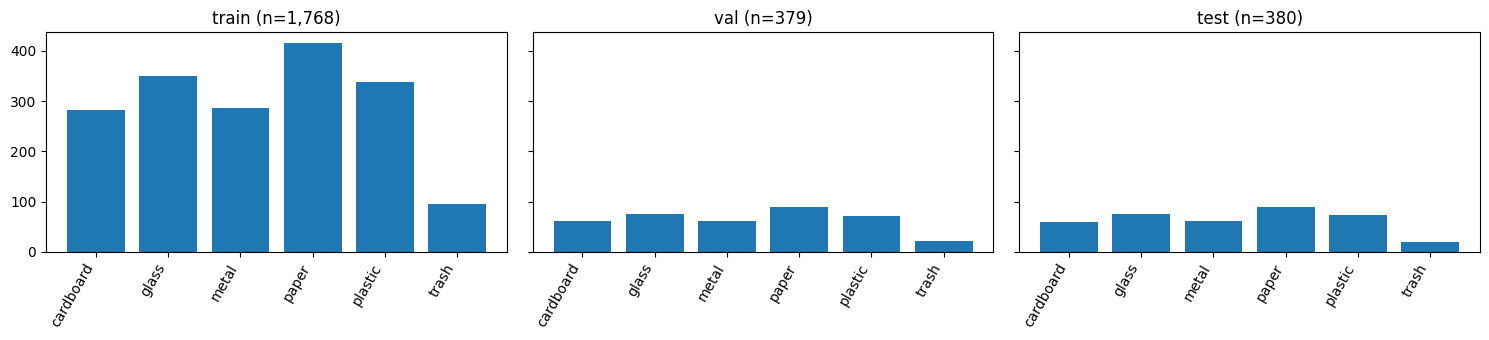

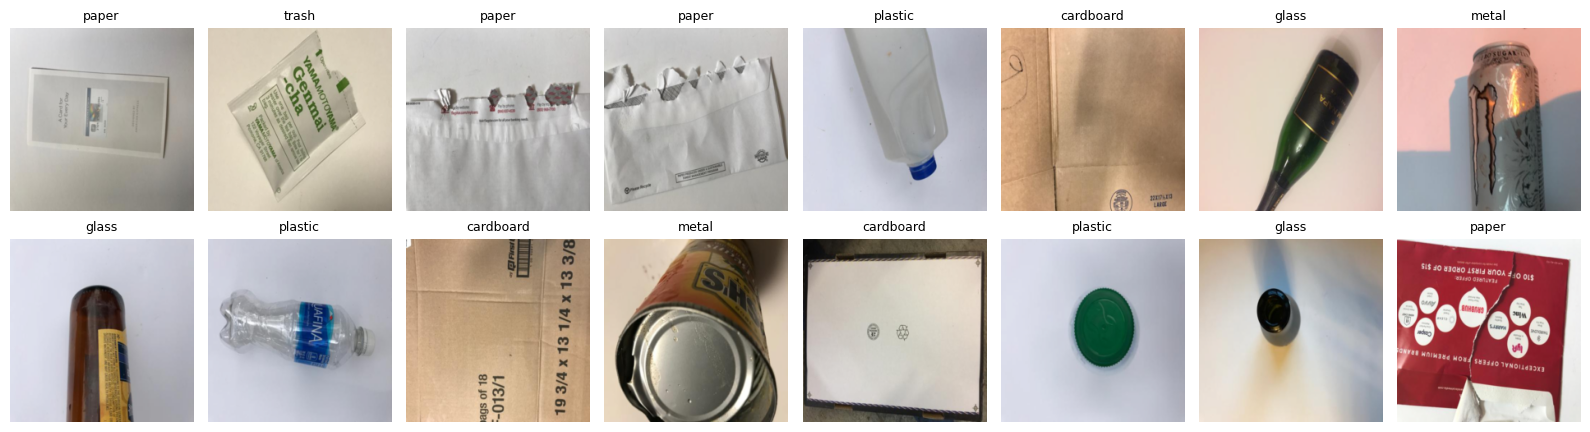

In [68]:
counts_df = pd.DataFrame({name: np.bincount(all_targets[idx], minlength=NUM_CLASSES)
                          for name, idx in [("all", pool), ("train", train_idx), ("val", val_idx), ("test", test_idx)]},
                         index=class_names)
counts_df["% of all"] = (100 * counts_df["all"] / counts_df["all"].sum()).round(1)
display(counts_df)
print(f"imbalance ratio (มากสุด/น้อยสุด) = {counts_df['all'].max() / counts_df['all'].min():.2f}")

# ขนาดภาพต้นฉบับ (สุ่ม 200 ภาพ)
from PIL import Image
sizes = pd.Series([Image.open(full_eval.samples[i][0]).size
                   for i in np.random.default_rng(SEED).choice(len(full_eval), 200, replace=False)]).value_counts()
print("ขนาดภาพต้นฉบับ (กว้าง, สูง) ที่พบ:\n", sizes.head())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for a, (name, idx) in zip(ax, [("train", train_idx), ("val", val_idx), ("test", test_idx)]):
    counts = np.bincount(all_targets[idx], minlength=NUM_CLASSES)
    a.bar(range(NUM_CLASSES), counts); a.set_title(f"{name} (n={len(idx):,})")
    a.set_xticks(range(NUM_CLASSES)); a.set_xticklabels(class_names, rotation=60, ha="right")
plt.tight_layout(); plt.show()

def denorm(x):
    x = x.cpu().numpy().transpose(1, 2, 0) * np.array(STD) + np.array(MEAN)
    return np.clip(x, 0, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for a, i in zip(axes.ravel(), np.random.choice(len(val_ds), 16, replace=False)):
    img, y = val_ds[i]
    a.imshow(denorm(img)); a.set_title(class_names[y], fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Data Augmentation (กลุ่มออกแบบเอง)
ภาพในชุดข้อมูลเป็นวัตถุขยะชิ้นเดียว (ขวด กระป๋อง กล่อง กระดาษ ถุง) ถ่ายบนพื้นหลังสีอ่อน ในชีวิตจริงขยะ **วางได้ทุกทิศทาง** ถ่ายจากระยะและแสงต่างกัน
แต่ **สีและพื้นผิวของวัสดุ** เป็นข้อมูลสำคัญที่ใช้แยก class (เช่น แก้วใส/เขียว/น้ำตาล, กระดาษลูกฟูกสีน้ำตาล, ความมันวาวของโลหะ) จึงไม่ควรเปลี่ยนสี (hue) แรง

| Augmentation | ค่าที่ใช้ | เหตุผล (ภาพจริงมีความแปรผันแบบนี้หรือไม่) |
|---|---|---|
| `RandomResizedCrop` | scale = (0.7, 1.0) | ระยะกล้องและตำแหน่งวัตถุในภาพไม่เท่ากัน; ไม่ครอปเล็กกว่า 70% เพื่อไม่ให้วัตถุหลุดกรอบ |
| `RandomHorizontalFlip` | p = 0.5 | ขยะไม่มีด้านซ้าย/ขวาที่มีความหมาย ขวดที่พลิกยังเป็นขวด (ต่างจากป้ายจราจร) |
| `RandomVerticalFlip` | p = 0.5 | ขยะที่ทิ้งแล้ววางได้ทุกทิศทาง (ขวดล้มคว่ำ กล่องกลับด้าน) ถ่ายจากมุมบน จึงไม่มี "ด้านบน" ตายตัว |
| `RandomRotation` | ±20° | วัตถุวางเอียงมุมต่าง ๆ; จำกัดที่ 20° เพื่อไม่ให้มุมดำที่เกิดจากการหมุนกินพื้นที่มาก |
| `ColorJitter` | brightness 0.25, contrast 0.25, saturation 0.15, hue 0.02 | แสงในการถ่ายต่างกัน (ในร่ม/นอกอาคาร/แฟลช); hue ตั้งไว้น้อยมากเพราะสีเป็นตัวบอกชนิดวัสดุ |
| ไม่ใช้ Grayscale | – | สีเป็นข้อมูลสำคัญ (แก้วสีเขียว กระดาษลังสีน้ำตาล) การตัดสีทำให้ cardboard/paper และ glass/plastic แยกยากขึ้น |

**การทดลอง C (เพิ่มเติม):** augment แรงขึ้น (ครอป 0.5–1.0, หมุน ±30°, jitter แรงขึ้น และ `RandomErasing` จำลองวัตถุถูกบังบางส่วน) เพื่อดูว่า augment มากขึ้นช่วยหรือทำให้ underfit

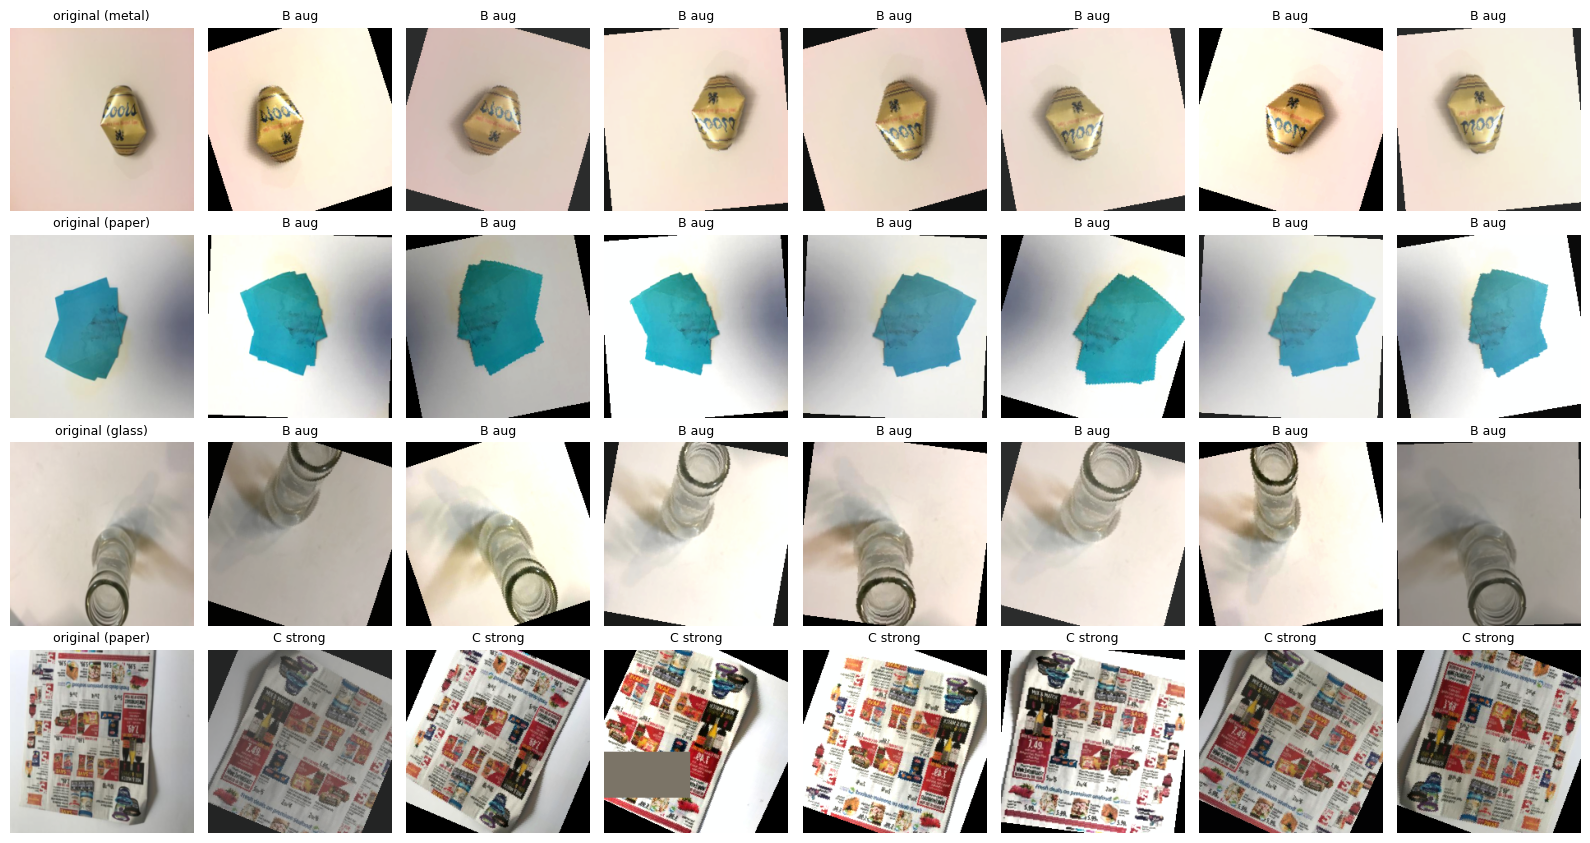

In [69]:
aug_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.7, 1.0)),        # ระยะกล้อง/ตำแหน่งวัตถุต่างกัน
    transforms.RandomHorizontalFlip(p=0.5),                    # ขยะไม่มีซ้าย/ขวา
    transforms.RandomVerticalFlip(p=0.5),                      # ขยะวางได้ทุกทิศทาง (ถ่ายจากมุมบน)
    transforms.RandomRotation(20),                             # วางเอียง
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15, hue=0.02),  # แสงต่างกัน, hue น้อย
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

strong_aug_tf = transforms.Compose([                           # การทดลอง C: augment แรงขึ้น
    transforms.RandomResizedCrop(S, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.25, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),      # จำลองวัตถุถูกบังบางส่วน
])

full_aug = make_full_dataset(aug_tf)
full_strong = make_full_dataset(strong_aug_tf)
train_ds = {
    "A_no_aug":     Subset(full_eval,   train_idx),   # การทดลอง A
    "B_aug":        Subset(full_aug,    train_idx),   # การทดลอง B
    "C_strong_aug": Subset(full_strong, train_idx),   # การทดลอง C (เพิ่มเติม)
}

# ตัวอย่างภาพหลัง augment: แถวละ 1 ภาพต้นฉบับ + 7 แบบที่ถูก augment (แถว 1-3 = B, แถว 4 = C)
rng = np.random.default_rng(SEED)
picks = rng.choice(train_idx, 4, replace=False)
fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
for r, (row, i) in enumerate(zip(axes, picks)):
    ds_aug, tag = (full_aug, "B aug") if r < 3 else (full_strong, "C strong")
    row[0].imshow(denorm(full_eval[i][0])); row[0].set_title(f"original ({class_names[all_targets[i]]})", fontsize=9)
    for a in row[1:]:
        a.imshow(denorm(ds_aug[i][0])); a.set_title(tag, fontsize=9)
    for a in row: a.axis("off")
plt.tight_layout(); plt.show()

In [70]:
loader_kw = dict(batch_size=CFG["batch_size"], num_workers=CFG["num_workers"], pin_memory=True)
val_loader  = DataLoader(val_ds,  shuffle=False, **loader_kw)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kw)
def make_train_loader(exp):
    set_seed()   # ลำดับข้อมูลเหมือนกันทุกการทดลอง เพื่อการเปรียบเทียบที่ยุติธรรม
    return DataLoader(train_ds[exp], shuffle=True, **loader_kw)

## 4. Model: Transfer Learning ด้วย ResNet-18
ใช้ pretrained weights จาก ImageNet แล้วเปลี่ยนชั้นสุดท้ายให้เท่ากับจำนวน class
(กลุ่มสามารถเปลี่ยนเป็น EfficientNet, MobileNet, ConvNeXt ฯลฯ ได้ แต่ต้องใช้โมเดลเดียวกันในการทดลอง A และ B)

In [71]:
def build_model(pretrained=True):
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    return m.to(device)

def build_training_objects(model):
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"])
    scaler = torch.amp.GradScaler("cuda")   # mixed precision: เร็วขึ้นและใช้หน่วยความจำ GPU น้อยลง
    return optimizer, scheduler, scaler

criterion = nn.CrossEntropyLoss()

## 5. Checkpoint
แต่ละ checkpoint เก็บ **model + optimizer + scheduler + scaler + history + epoch** เพื่อให้เทรนต่อได้เหมือนไม่เคยหยุด
* `checkpoints/<การทดลอง>/last.pt` บันทึกทุก epoch (ใช้ resume เมื่อ session หลุดหรือหมดเวลา)
* `checkpoints/<การทดลอง>/best.pt` บันทึกเมื่อ validation loss ต่ำที่สุด (ใช้ประเมินผลและนำไปใช้งาน)

In [72]:
def ckpt_paths(exp):
    d = f"{CKPT_DIR}/{exp}"; os.makedirs(d, exist_ok=True)
    return f"{d}/last.pt", f"{d}/best.pt"

def save_checkpoint(path, epoch, model, optimizer, scheduler, scaler, history, best_val_loss, bad_epochs, stopped_early):
    torch.save({
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss,
        "bad_epochs": bad_epochs,
        "stopped_early": stopped_early,
        "class_names": class_names,
        "cfg": CFG,
    }, path)

def load_checkpoint(path, model, optimizer=None, scheduler=None, scaler=None):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None: optimizer.load_state_dict(ckpt["optimizer_state"])
    if scheduler is not None: scheduler.load_state_dict(ckpt["scheduler_state"])
    if scaler is not None:    scaler.load_state_dict(ckpt["scaler_state"])
    return ckpt

## 6. Training loop (resume อัตโนมัติถ้ามี `last.pt`)

In [73]:
def run_epoch(model, loader, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.amp.autocast("cuda"):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def train_model(exp, until_epoch=None):
    until_epoch = until_epoch or CFG["epochs"]
    last_path, best_path = ckpt_paths(exp)
    set_seed()
    model = build_model()
    optimizer, scheduler, scaler = build_training_objects(model)
    train_loader = make_train_loader(exp)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
    start_epoch, best_val_loss, bad_epochs, stopped_early = 1, float("inf"), 0, False
    if os.path.exists(last_path):   # ---- RESUME ----
        ckpt = load_checkpoint(last_path, model, optimizer, scheduler, scaler)
        start_epoch = ckpt["epoch"] + 1
        history, best_val_loss = ckpt["history"], ckpt["best_val_loss"]
        bad_epochs, stopped_early = ckpt["bad_epochs"], ckpt["stopped_early"]
        print(f"[{exp}] Resumed from {last_path}: epoch {ckpt['epoch']} เสร็จแล้ว, best_val_loss={best_val_loss:.4f}")
        if stopped_early:
            print(f"[{exp}] การทดลองนี้ early stop ไปแล้ว ไม่ต้องเทรนต่อ"); return history

    for epoch in range(start_epoch, until_epoch + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader)
        lr = optimizer.param_groups[0]["lr"]
        scheduler.step()
        for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc, lr]):
            history[k].append(v)

        improved = va_loss < best_val_loss
        if improved:
            best_val_loss, bad_epochs = va_loss, 0
        else:
            bad_epochs += 1
        stopped_early = bad_epochs >= CFG["patience"]
        state = (model, optimizer, scheduler, scaler, history, best_val_loss, bad_epochs, stopped_early)
        save_checkpoint(last_path, epoch, *state)
        if improved:
            save_checkpoint(best_path, epoch, *state)

        print(f"[{exp}] Epoch {epoch:02d}/{CFG['epochs']} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.3f} | lr {lr:.2e} | {time.time()-t0:.0f}s"
              + ("  <- best" if improved else ""))
        if stopped_early:
            print(f"[{exp}] Early stopping: val loss ไม่ดีขึ้น {CFG['patience']} epochs ติดกัน"); break

    best_ep = int(np.argmin(history["val_loss"])) + 1
    if until_epoch == CFG["epochs"] and not stopped_early and best_ep >= len(history["val_loss"]) - 1:
        print(f"[{exp}] ⚠️ val loss ยังลดลงอยู่ช่วงท้าย อาจยังไม่ converge: พิจารณาเพิ่ม CFG['epochs']")
    return history

histories = {}

### 6.1 การทดลอง A: ไม่ augment

In [74]:
histories["A_no_aug"] = train_model("A_no_aug")

[A_no_aug] Epoch 01/50 | train loss 0.6301 acc 0.764 | val loss 0.4523 acc 0.847 | lr 3.00e-04 | 84s  <- best
[A_no_aug] Epoch 02/50 | train loss 0.1315 acc 0.963 | val loss 0.3085 acc 0.905 | lr 3.00e-04 | 8s  <- best
[A_no_aug] Epoch 03/50 | train loss 0.0392 acc 0.992 | val loss 0.2569 acc 0.916 | lr 2.99e-04 | 8s  <- best
[A_no_aug] Epoch 04/50 | train loss 0.0143 acc 0.997 | val loss 0.3049 acc 0.894 | lr 2.97e-04 | 8s
[A_no_aug] Epoch 05/50 | train loss 0.0096 acc 0.998 | val loss 0.2760 acc 0.926 | lr 2.95e-04 | 7s
[A_no_aug] Epoch 06/50 | train loss 0.0054 acc 0.998 | val loss 0.2826 acc 0.923 | lr 2.93e-04 | 8s
[A_no_aug] Epoch 07/50 | train loss 0.0031 acc 0.999 | val loss 0.2379 acc 0.931 | lr 2.89e-04 | 8s  <- best
[A_no_aug] Epoch 08/50 | train loss 0.0027 acc 0.999 | val loss 0.2401 acc 0.931 | lr 2.86e-04 | 7s
[A_no_aug] Epoch 09/50 | train loss 0.0022 acc 0.999 | val loss 0.2386 acc 0.937 | lr 2.81e-04 | 7s
[A_no_aug] Epoch 10/50 | train loss 0.0020 acc 0.999 | val loss

### 6.2 การทดลอง B: augment (พร้อมสาธิตการ resume)
รอบแรกเทรนถึง epoch 5 (จำลองว่า session หมดเวลา) จากนั้นเรียกซ้ำ ซึ่งจะสร้างโมเดลและ optimizer ใหม่ทั้งหมด
ผลลัพธ์ต้องขึ้นว่า **Resumed from ... epoch 5** และเทรนต่อที่ epoch 6 ไม่ใช่เริ่มจาก epoch 1

In [75]:
_ = train_model("B_aug", until_epoch=5)          # รอบแรก: หยุดที่ epoch 5
torch.cuda.empty_cache()
histories["B_aug"] = train_model("B_aug")        # รอบสอง: resume จาก last.pt จนจบ

[B_aug] Epoch 01/50 | train loss 0.8064 acc 0.706 | val loss 1.0223 acc 0.678 | lr 3.00e-04 | 13s  <- best
[B_aug] Epoch 02/50 | train loss 0.4109 acc 0.862 | val loss 0.5843 acc 0.784 | lr 3.00e-04 | 13s  <- best
[B_aug] Epoch 03/50 | train loss 0.2839 acc 0.896 | val loss 0.5417 acc 0.826 | lr 2.99e-04 | 13s  <- best
[B_aug] Epoch 04/50 | train loss 0.2323 acc 0.921 | val loss 0.6804 acc 0.781 | lr 2.97e-04 | 13s
[B_aug] Epoch 05/50 | train loss 0.2328 acc 0.915 | val loss 0.4754 acc 0.865 | lr 2.95e-04 | 13s  <- best
[B_aug] Resumed from /kaggle/working/checkpoints/B_aug/last.pt: epoch 5 เสร็จแล้ว, best_val_loss=0.4754
[B_aug] Epoch 06/50 | train loss 0.1209 acc 0.959 | val loss 0.4147 acc 0.860 | lr 2.93e-04 | 13s  <- best
[B_aug] Epoch 07/50 | train loss 0.0722 acc 0.981 | val loss 0.3339 acc 0.897 | lr 2.89e-04 | 13s  <- best
[B_aug] Epoch 08/50 | train loss 0.0530 acc 0.985 | val loss 0.4220 acc 0.905 | lr 2.86e-04 | 14s
[B_aug] Epoch 09/50 | train loss 0.0428 acc 0.988 | val lo

### 6.3 การทดลอง C (เพิ่มเติม): augment แรงขึ้น
ตั้งค่าอื่นเหมือน A และ B ทุกอย่าง (โมเดล, lr, batch size, epochs, patience, seed) ต่างกันแค่ augmentation

In [76]:
histories["C_strong_aug"] = train_model("C_strong_aug")
torch.cuda.empty_cache()

[C_strong_aug] Epoch 01/50 | train loss 0.8661 acc 0.687 | val loss 0.7074 acc 0.752 | lr 3.00e-04 | 14s  <- best
[C_strong_aug] Epoch 02/50 | train loss 0.5103 acc 0.821 | val loss 0.7198 acc 0.734 | lr 3.00e-04 | 13s
[C_strong_aug] Epoch 03/50 | train loss 0.4046 acc 0.852 | val loss 0.5049 acc 0.818 | lr 2.99e-04 | 13s  <- best
[C_strong_aug] Epoch 04/50 | train loss 0.3117 acc 0.895 | val loss 0.3902 acc 0.847 | lr 2.97e-04 | 13s  <- best
[C_strong_aug] Epoch 05/50 | train loss 0.3142 acc 0.889 | val loss 0.3617 acc 0.868 | lr 2.95e-04 | 13s  <- best
[C_strong_aug] Epoch 06/50 | train loss 0.2655 acc 0.903 | val loss 0.4122 acc 0.842 | lr 2.93e-04 | 13s
[C_strong_aug] Epoch 07/50 | train loss 0.1917 acc 0.939 | val loss 0.3961 acc 0.887 | lr 2.89e-04 | 13s
[C_strong_aug] Epoch 08/50 | train loss 0.2444 acc 0.912 | val loss 0.3479 acc 0.876 | lr 2.86e-04 | 13s  <- best
[C_strong_aug] Epoch 09/50 | train loss 0.1882 acc 0.934 | val loss 0.3472 acc 0.876 | lr 2.81e-04 | 13s  <- best
[

In [77]:
for root, _, files in os.walk(CKPT_DIR):
    for f in sorted(files):
        p = os.path.join(root, f)
        print(f"{os.path.relpath(p, CKPT_DIR):22s} {os.path.getsize(p)/1e6:.1f} MB")

C_strong_aug/best.pt   134.3 MB
C_strong_aug/last.pt   134.3 MB
A_no_aug/best.pt       134.3 MB
A_no_aug/last.pt       134.3 MB
B_aug/best.pt          134.3 MB
B_aug/last.pt          134.3 MB


## 7. Loss Curves และการเปรียบเทียบการทดลอง

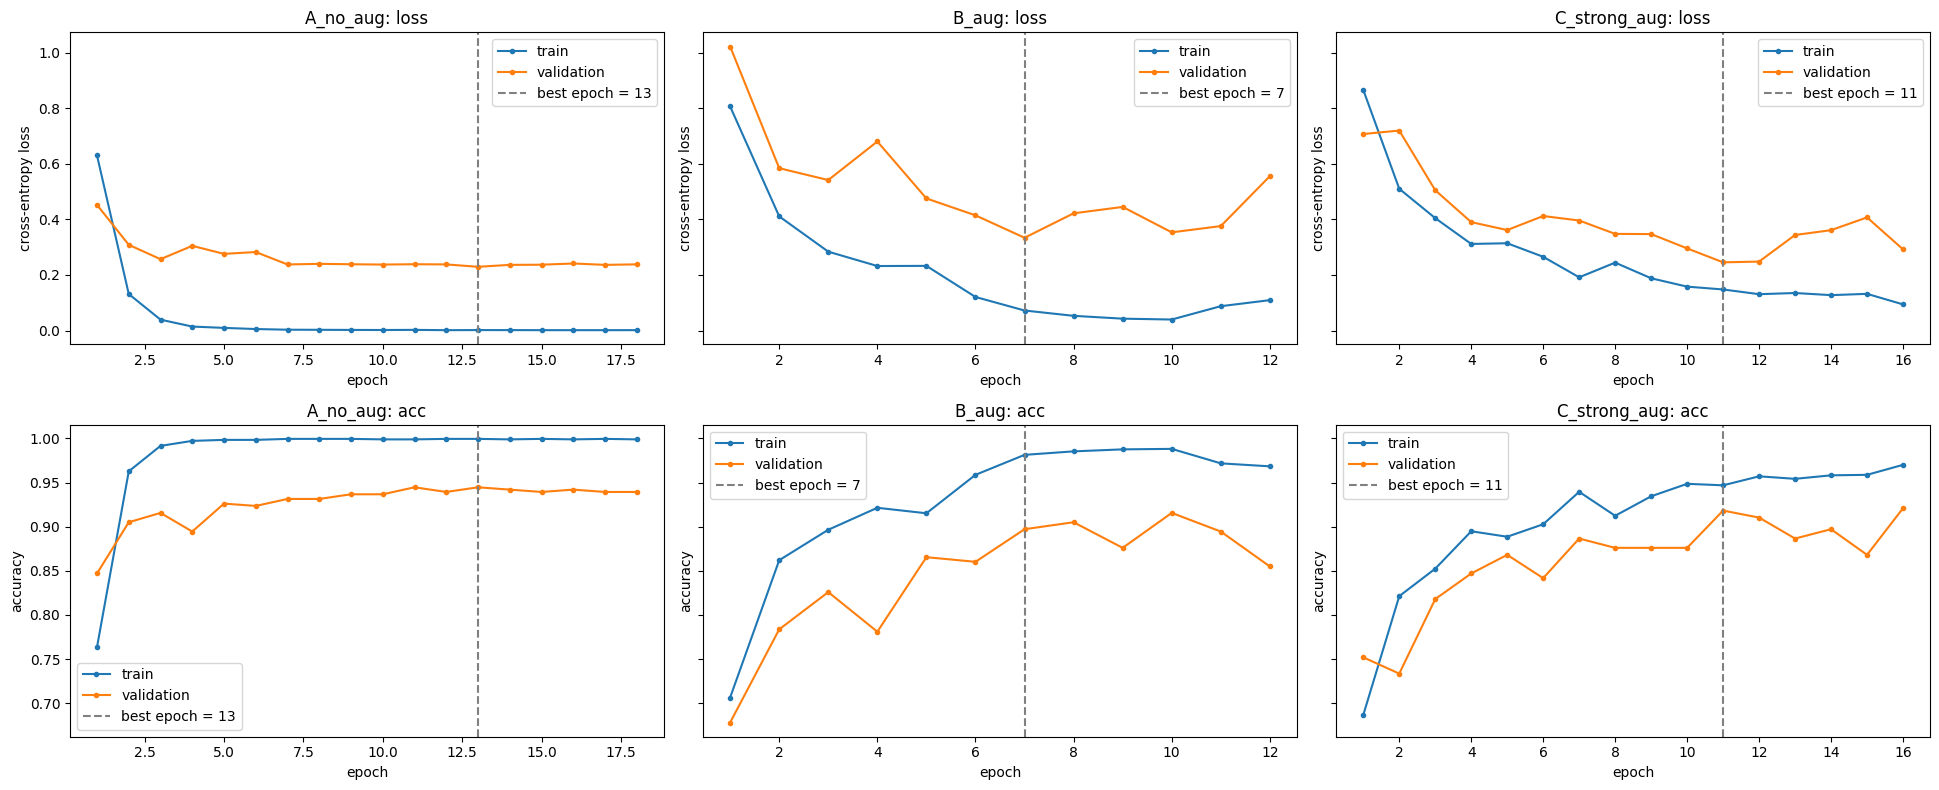

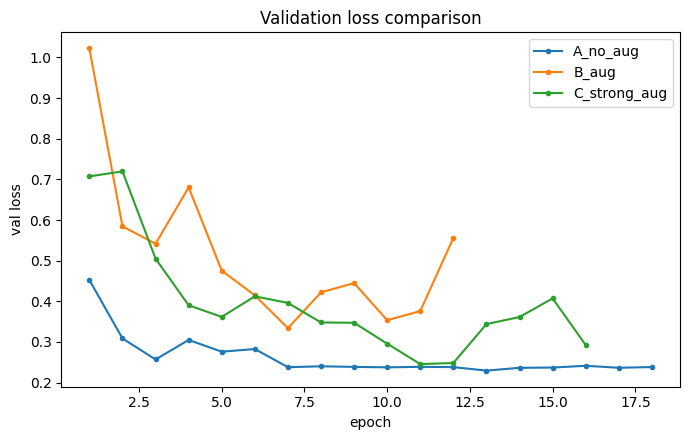

In [78]:
exps = list(histories)
fig, axes = plt.subplots(2, len(exps), figsize=(6.5 * len(exps), 8), sharey="row", squeeze=False)
for j, exp in enumerate(exps):
    h = histories[exp]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    best_ep = int(np.argmin(h["val_loss"])) + 1
    for i, (metric, ylabel) in enumerate([("loss", "cross-entropy loss"), ("acc", "accuracy")]):
        a = axes[i, j]
        a.plot(ep, h[f"train_{metric}"], "o-", ms=3, label="train")
        a.plot(ep, h[f"val_{metric}"], "o-", ms=3, label="validation")
        a.axvline(best_ep, ls="--", c="gray", label=f"best epoch = {best_ep}")
        a.set(title=f"{exp}: {metric}", xlabel="epoch", ylabel=ylabel); a.legend()
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/loss_curves.png", dpi=150); plt.show()

plt.figure(figsize=(7, 4.5))
for exp in exps:
    plt.plot(np.arange(1, len(histories[exp]["val_loss"]) + 1), histories[exp]["val_loss"], "o-", ms=3, label=exp)
plt.title("Validation loss comparison"); plt.xlabel("epoch"); plt.ylabel("val loss"); plt.legend()
plt.tight_layout(); plt.show()

In [79]:
rows = []
for exp, h in histories.items():
    b = int(np.argmin(h["val_loss"]))
    rows.append({
        "experiment": exp,
        "epochs trained": len(h["val_loss"]),
        "best epoch": b + 1,
        "best val loss": h["val_loss"][b],
        "val acc @best": h["val_acc"][b],
        "train loss @best": h["train_loss"][b],
        "gap (val - train loss)": h["val_loss"][b] - h["train_loss"][b],
    })
summary = pd.DataFrame(rows).set_index("experiment")
display(summary.round(4))

FINAL_EXP = summary["best val loss"].idxmin()   # เลือกจาก validation เท่านั้น ห้ามดู test
print("โมเดลสุดท้าย:", FINAL_EXP)

,epochs trained,best epoch,best val loss,val acc @best,train loss @best,gap (val - train loss)
experiment,,,,,,
A_no_aug,18,13,0.2295,0.9446,0.0017,0.2277
B_aug,12,7,0.3339,0.8971,0.0722,0.2618
C_strong_aug,16,11,0.2455,0.9182,0.1479,0.0976


โมเดลสุดท้าย: A_no_aug


## 8. Model Evaluation บน Test Set (โหลด `best.pt` ของโมเดลสุดท้าย, ประเมินครั้งเดียว)

In [80]:
best_model = build_model(pretrained=False)
ckpt = load_checkpoint(ckpt_paths(FINAL_EXP)[1], best_model)
best_model.eval()
print(f"Loaded {FINAL_EXP}/best.pt จาก epoch {ckpt['epoch']} (val loss {ckpt['best_val_loss']:.4f})")

y_true, y_pred = [], []
with torch.no_grad(), torch.amp.autocast("cuda"):
    for x, y in test_loader:
        y_pred.append(best_model(x.to(device)).argmax(1).cpu().numpy())
        y_true.append(y.numpy())
y_true, y_pred = np.concatenate(y_true), np.concatenate(y_pred)

test_acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {test_acc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

json.dump({"final_experiment": FINAL_EXP, "best_epoch": ckpt["epoch"], "test_accuracy": test_acc,
           "report": classification_report(y_true, y_pred, target_names=class_names, output_dict=True)},
          open(f"{WORK_DIR}/test_metrics.json", "w"), indent=2)

Loaded A_no_aug/best.pt จาก epoch 13 (val loss 0.2295)
Test accuracy: 0.9368

              precision    recall  f1-score   support

   cardboard      0.982     0.917     0.948        60
       glass      0.944     0.882     0.912        76
       metal      0.922     0.952     0.937        62
       paper      0.936     0.989     0.962        89
     plastic      0.918     0.918     0.918        73
       trash      0.909     1.000     0.952        20

    accuracy                          0.937       380
   macro avg      0.935     0.943     0.938       380
weighted avg      0.938     0.937     0.937       380



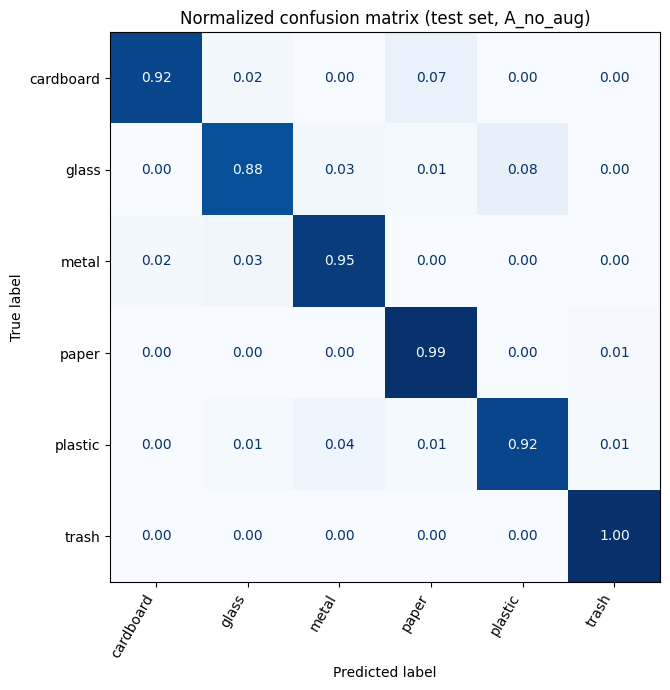

In [81]:
cm = confusion_matrix(y_true, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
plt.xticks(rotation=60, ha="right"); plt.title(f"Normalized confusion matrix (test set, {FINAL_EXP})")
plt.tight_layout(); plt.show()

### ตัวอย่างภาพที่โมเดลทำนายผิด (error analysis)

ทำนายผิด 24 จาก 380 ภาพ


,true,predicted,count
0,glass,plastic,6
1,cardboard,paper,4
2,plastic,metal,3
3,glass,metal,2
4,metal,glass,2
5,cardboard,glass,1
6,glass,paper,1
7,metal,cardboard,1


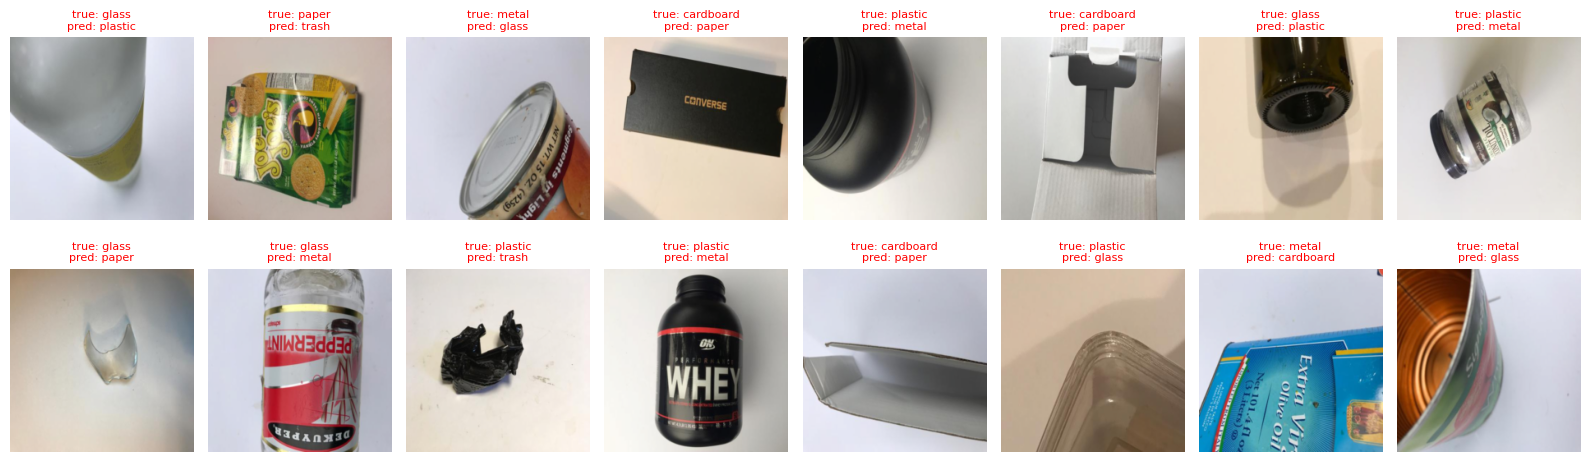

In [82]:
wrong = np.where(y_true != y_pred)[0]
print(f"ทำนายผิด {len(wrong)} จาก {len(y_true)} ภาพ")

# คู่ class ที่สับสนบ่อยที่สุด (นับจำนวนภาพจริง)
cm_raw = confusion_matrix(y_true, y_pred)
pairs = [(class_names[i], class_names[j], cm_raw[i, j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES)
         if i != j and cm_raw[i, j] > 0]
confusions = pd.DataFrame(pairs, columns=["true", "predicted", "count"]).sort_values("count", ascending=False)
display(confusions.head(8).reset_index(drop=True))

if len(wrong):
    show = np.random.default_rng(SEED).choice(wrong, min(16, len(wrong)), replace=False)
    fig, axes = plt.subplots(2, 8, figsize=(16, 5))
    for a in axes.ravel(): a.axis("off")
    for a, i in zip(axes.ravel(), show):
        img, _ = test_ds[i]
        a.imshow(denorm(img))
        a.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]}", fontsize=8, color="red")
    plt.tight_layout(); plt.show()

## 9. อภิปรายผล
ตัวเลขทุกตัวในคำตอบด้านล่างคำนวณจากผลการรันจริงของ notebook นี้ (เซลล์ถัดไป) ส่วนเหตุผลอธิบายไว้ในแต่ละข้อ

In [83]:
from IPython.display import Markdown
rep = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
macro_f1 = rep["macro avg"]["f1-score"]
f1s = pd.Series({c: rep[c]["f1-score"] for c in class_names}).sort_values()
worst, best = f1s.index[0], f1s.index[-1]
top = confusions.head(3).values.tolist() if len(confusions) else []
worst_conf = confusions[confusions["true"] == worst].head(1).values.tolist()
NAME = {"A_no_aug": "A (ไม่ augment)", "B_aug": "B (augment ที่ออกแบบ)", "C_strong_aug": "C (augment แรงขึ้น)"}
S = summary
H = histories
last_tr = {e: H[e]["train_loss"][-1] for e in H}
rank = S["best val loss"].sort_values()
def cmp(a, b, lower_better=True):
    return "ต่ำกว่า" if a < b else ("สูงกว่า" if a > b else "เท่ากับ")

def conv_line(e):
    h = H[e]; b = int(np.argmin(h["val_loss"])) + 1; n = len(h["val_loss"])
    return (f"* **{NAME[e]}**: val loss ต่ำสุดที่ epoch **{b}** ({h['val_loss'][b-1]:.4f}) เทรนทั้งหมด {n} epochs — "
            + (f"early stopping หยุดเองเพราะ val loss ไม่ดีขึ้น {CFG['patience']} epochs ติดกัน" if n < CFG["epochs"]
               else "เทรนครบทุก epoch โดยไม่ early stop ⚠️ ควรเพิ่ม `epochs`"))

A, B = "A_no_aug", "B_aug"
gA, gB = S.loc[A, "gap (val - train loss)"], S.loc[B, "gap (val - train loss)"]
vlA, vlB = S.loc[A, "best val loss"], S.loc[B, "best val loss"]
vaA, vaB = S.loc[A, "val acc @best"], S.loc[B, "val acc @best"]
epA, epB = S.loc[A, "best epoch"], S.loc[B, "best epoch"]
over = [f"* **{NAME[e]}**: train loss ช่วงท้าย = {last_tr[e]:.4f}, ช่องว่าง val − train loss ที่ best epoch = **{S.loc[e, 'gap (val - train loss)']:.4f}**" for e in H]

if rank.index[0] == A:
    aug_text = (f"* augmentation **ไม่ได้ช่วย** ในชุดข้อมูลนี้: A ได้ best val loss ต่ำที่สุด ({vlA:.4f})"
        + "".join(f", {NAME[e]} = {S.loc[e,'best val loss']:.4f}" for e in rank.index[1:]) + "\n"
        "* เหตุผลที่เป็นไปได้: ภาพในชุดนี้ถ่ายใน**สภาพควบคุม** (พื้นหลังสีอ่อนแบบเดียวกัน กล้องเดียวกัน ขนาด 512×384 วัตถุอยู่กลางภาพ) "
        "และ validation/test มาจากการกระจายเดียวกับ train ความแปรผันที่ augmentation จำลอง (หมุน พลิก ครอป แสง) จึงแทบไม่มีใน val/test "
        "โมเดลที่ไม่ augment จึงได้เปรียบ ส่วน augmentation ทำให้งาน train ยากขึ้นและ val loss แกว่งมากขึ้น จน early stopping หยุดก่อนที่ประโยชน์จะปรากฏ\n"
        "* ข้อสังเกต: ถ้านำโมเดลไปใช้กับภาพขยะจริง (พื้นหลังหลากหลาย มุมกล้องต่างกัน) โมเดลที่ augment น่าจะทนทานกว่า แต่ val/test ชุดนี้วัดข้อนั้นไม่ได้")
else:
    aug_text = (f"* augmentation **ช่วย**: โมเดลที่ดีที่สุดคือ {NAME[rank.index[0]]} (best val loss {rank.iloc[0]:.4f}) เทียบกับ A = {vlA:.4f} "
        "เพราะโมเดลเห็นภาพที่หลากหลายขึ้น จึงจำภาพเฉพาะตัวใน train ได้ยากขึ้นและ generalize ได้ดีกว่า")
C_text = ""
if "C_strong_aug" in S.index:
    vlC = S.loc["C_strong_aug", "best val loss"]
    C_text = (f"\n* C เทียบ B: best val loss {vlC:.4f} vs {vlB:.4f} → "
              + ("augment แรงขึ้นดีกว่า B แสดงว่า B ยัง augment น้อยไปหรือ val loss ของ B แกว่งจน early stop เร็วเกินไป" if vlC < vlB
                 else "augment แรงขึ้นไม่ช่วย แสดงว่าภาพ train เริ่มต่างจากภาพจริงมากเกินไป"))

txt = f"""
**1. Convergence**
{chr(10).join(conv_line(e) for e in H)}

{'ทุกการทดลองหยุดด้วย early stopping ก่อนครบ ' + str(CFG['epochs']) + ' epochs' if all(len(H[e]['val_loss']) < CFG['epochs'] for e in H) else '⚠️ บางการทดลองยังไม่ early stop'} — val loss ลดลงแล้วนิ่งหรือเพิ่มขึ้นหลัง best epoch (เส้นประในกราฟ) ขณะที่ train loss ยังลดต่อ จึงถือว่า converge แล้ว และ `best.pt` เก็บโมเดล ณ จุดที่ val loss ต่ำสุด

**2. Overfitting**
{chr(10).join(over)}
* A: train loss ลงไปเกือบ 0 (จำ train set ได้เกือบหมด) ขณะที่ val loss หยุดลดตั้งแต่ epoch {epA} → overfit ชัดเจน เพราะ train มีเพียง {len(train_idx):,} ภาพ แต่ ResNet-18 มีพารามิเตอร์ ~11 ล้านตัว
* B: train loss ช่วงท้าย{cmp(last_tr[B], last_tr[A])} A ({last_tr[B]:.4f} vs {last_tr[A]:.4f}) แสดงว่า augmentation ทำให้จำ train set ได้ยากขึ้น (regularization) แต่ช่องว่าง val − train ที่ best epoch ของ B {cmp(gB, gA)} A ({gB:.4f} vs {gA:.4f}){" เพราะ val loss ของ B เองสูงกว่า A จึงไม่ได้แปลว่า B generalize ดีกว่า" if gB > gA else " สอดคล้องกับที่ augmentation ลด overfitting"}

**3. ผลของ augmentation**
* best val loss: A = {vlA:.4f} → B = {vlB:.4f}; val accuracy: A = {vaA:.3f} → B = {vaB:.3f}
* B ได้ best epoch ที่ {epB} เทียบกับ A ที่ {epA}; train loss ของ B สูงกว่า A ตลอดและกราฟ val loss แกว่งกว่า เพราะภาพ train ถูกสุ่มครอป/พลิก/หมุน/เปลี่ยนแสงทุก epoch
{aug_text}{C_text}

**4. Test performance (โมเดลสุดท้าย = {NAME[FINAL_EXP]} เลือกจาก val loss ต่ำสุด, best epoch {ckpt['epoch']})**
* Test accuracy = **{test_acc:.4f}**, macro F1 = **{macro_f1:.4f}** (ใกล้เคียง val accuracy {S.loc[FINAL_EXP, 'val acc @best']:.4f} แสดงว่าไม่ได้ overfit กับ validation set)
* F1 ราย class: {", ".join(f"{c} {v:.3f}" for c, v in f1s.sort_values(ascending=False).items())}
* ดีที่สุด: **{best}** (F1 = {f1s[best]:.3f}); แย่ที่สุด: **{worst}** (F1 = {f1s[worst]:.3f}){f" ซึ่งถูกทำนายเป็น {worst_conf[0][1]} บ่อยที่สุด ({worst_conf[0][2]} ภาพ)" if worst_conf else ""}
* class ที่วัสดุมีลักษณะเฉพาะชัด (สีน้ำตาลของ cardboard, ผิวกระดาษ, ความมันวาวของโลหะ) ทำได้ดี ส่วน glass กับ plastic ทำได้แย่กว่าเพราะทั้งคู่เป็นขวด/ภาชนะใสที่รูปร่างคล้ายกัน แยกได้จากความหนาและการสะท้อนแสงเท่านั้น
* trash มีภาพน้อยที่สุด (test มีแค่ {int((y_true == class_names.index("trash")).sum())} ภาพ) ค่า F1 ของ class นี้จึงแกว่งได้มาก ผิดภาพเดียวก็เปลี่ยนหลายเปอร์เซ็นต์

**5. Error analysis**
* ทำนายผิด {int((y_true != y_pred).sum())} จาก {len(y_true)} ภาพ; คู่ที่สับสนบ่อยที่สุด: {"; ".join(f"{t} → {p} ({n} ภาพ)" for t, p, n in top) if top else "ไม่มี"}
* ลักษณะร่วมของภาพที่ผิด (ดูจากภาพตัวอย่างด้านบน): วัตถุใสที่สีพื้นหลังทะลุผ่าน (ขวดแก้ว vs ขวดพลาสติก), กระดาษลังที่บางหรือแบนคล้ายกระดาษทั่วไป, วัตถุที่สะท้อนแสงจนดูคล้ายโลหะ และภาพที่วัตถุเล็กหรือแสงจ้า

**6. แนวทางปรับปรุง**
* ใช้ **class-weighted loss** หรือ oversampling สำหรับ class ที่มีภาพน้อย (trash)
* ปรับ augmentation ให้เบาลง (ไม่หมุน/ไม่พลิกแนวตั้ง) หรือเพิ่ม `patience` ในการทดลองที่ augment เพราะ val loss แกว่งมากจน early stopping อาจหยุดเร็วเกินไป
* ลดค่า learning rate หรือ fine-tune แบบสองขั้น (ฝึก fc ก่อนแล้ว unfreeze ทั้งโมเดล) ให้ val loss ลดนิ่งขึ้น
* ลองโมเดลอื่น (EfficientNet-B0, ConvNeXt-Tiny) หรือภาพขนาดใหญ่ขึ้น เพื่อจับรายละเอียดพื้นผิวที่ใช้แยก glass/plastic
* ใช้ k-fold cross-validation เพราะ val/test มีชุดละ ~{len(val_idx)} ภาพ ผลจึงแกว่งได้จากการสุ่มแบ่ง และเก็บภาพขยะจากสภาพจริงมาทดสอบความทนทานของโมเดล
"""
display(Markdown(txt))


**1. Convergence**
* **A (ไม่ augment)**: val loss ต่ำสุดที่ epoch **13** (0.2295) เทรนทั้งหมด 18 epochs — early stopping หยุดเองเพราะ val loss ไม่ดีขึ้น 5 epochs ติดกัน
* **B (augment ที่ออกแบบ)**: val loss ต่ำสุดที่ epoch **7** (0.3339) เทรนทั้งหมด 12 epochs — early stopping หยุดเองเพราะ val loss ไม่ดีขึ้น 5 epochs ติดกัน
* **C (augment แรงขึ้น)**: val loss ต่ำสุดที่ epoch **11** (0.2455) เทรนทั้งหมด 16 epochs — early stopping หยุดเองเพราะ val loss ไม่ดีขึ้น 5 epochs ติดกัน

ทุกการทดลองหยุดด้วย early stopping ก่อนครบ 50 epochs — val loss ลดลงแล้วนิ่งหรือเพิ่มขึ้นหลัง best epoch (เส้นประในกราฟ) ขณะที่ train loss ยังลดต่อ จึงถือว่า converge แล้ว และ `best.pt` เก็บโมเดล ณ จุดที่ val loss ต่ำสุด

**2. Overfitting**
* **A (ไม่ augment)**: train loss ช่วงท้าย = 0.0015, ช่องว่าง val − train loss ที่ best epoch = **0.2277**
* **B (augment ที่ออกแบบ)**: train loss ช่วงท้าย = 0.1095, ช่องว่าง val − train loss ที่ best epoch = **0.2618**
* **C (augment แรงขึ้น)**: train loss ช่วงท้าย = 0.0942, ช่องว่าง val − train loss ที่ best epoch = **0.0976**
* A: train loss ลงไปเกือบ 0 (จำ train set ได้เกือบหมด) ขณะที่ val loss หยุดลดตั้งแต่ epoch 13 → overfit ชัดเจน เพราะ train มีเพียง 1,768 ภาพ แต่ ResNet-18 มีพารามิเตอร์ ~11 ล้านตัว
* B: train loss ช่วงท้ายสูงกว่า A (0.1095 vs 0.0015) แสดงว่า augmentation ทำให้จำ train set ได้ยากขึ้น (regularization) แต่ช่องว่าง val − train ที่ best epoch ของ B สูงกว่า A (0.2618 vs 0.2277) เพราะ val loss ของ B เองสูงกว่า A จึงไม่ได้แปลว่า B generalize ดีกว่า

**3. ผลของ augmentation**
* best val loss: A = 0.2295 → B = 0.3339; val accuracy: A = 0.945 → B = 0.897
* B ได้ best epoch ที่ 7 เทียบกับ A ที่ 13; train loss ของ B สูงกว่า A ตลอดและกราฟ val loss แกว่งกว่า เพราะภาพ train ถูกสุ่มครอป/พลิก/หมุน/เปลี่ยนแสงทุก epoch
* augmentation **ไม่ได้ช่วย** ในชุดข้อมูลนี้: A ได้ best val loss ต่ำที่สุด (0.2295), C (augment แรงขึ้น) = 0.2455, B (augment ที่ออกแบบ) = 0.3339
* เหตุผลที่เป็นไปได้: ภาพในชุดนี้ถ่ายใน**สภาพควบคุม** (พื้นหลังสีอ่อนแบบเดียวกัน กล้องเดียวกัน ขนาด 512×384 วัตถุอยู่กลางภาพ) และ validation/test มาจากการกระจายเดียวกับ train ความแปรผันที่ augmentation จำลอง (หมุน พลิก ครอป แสง) จึงแทบไม่มีใน val/test โมเดลที่ไม่ augment จึงได้เปรียบ ส่วน augmentation ทำให้งาน train ยากขึ้นและ val loss แกว่งมากขึ้น จน early stopping หยุดก่อนที่ประโยชน์จะปรากฏ
* ข้อสังเกต: ถ้านำโมเดลไปใช้กับภาพขยะจริง (พื้นหลังหลากหลาย มุมกล้องต่างกัน) โมเดลที่ augment น่าจะทนทานกว่า แต่ val/test ชุดนี้วัดข้อนั้นไม่ได้
* C เทียบ B: best val loss 0.2455 vs 0.3339 → augment แรงขึ้นดีกว่า B แสดงว่า B ยัง augment น้อยไปหรือ val loss ของ B แกว่งจน early stop เร็วเกินไป

**4. Test performance (โมเดลสุดท้าย = A (ไม่ augment) เลือกจาก val loss ต่ำสุด, best epoch 13)**
* Test accuracy = **0.9368**, macro F1 = **0.9380** (ใกล้เคียง val accuracy 0.9446 แสดงว่าไม่ได้ overfit กับ validation set)
* F1 ราย class: paper 0.962, trash 0.952, cardboard 0.948, metal 0.937, plastic 0.918, glass 0.912
* ดีที่สุด: **paper** (F1 = 0.962); แย่ที่สุด: **glass** (F1 = 0.912) ซึ่งถูกทำนายเป็น plastic บ่อยที่สุด (6 ภาพ)
* class ที่วัสดุมีลักษณะเฉพาะชัด (สีน้ำตาลของ cardboard, ผิวกระดาษ, ความมันวาวของโลหะ) ทำได้ดี ส่วน glass กับ plastic ทำได้แย่กว่าเพราะทั้งคู่เป็นขวด/ภาชนะใสที่รูปร่างคล้ายกัน แยกได้จากความหนาและการสะท้อนแสงเท่านั้น
* trash มีภาพน้อยที่สุด (test มีแค่ 20 ภาพ) ค่า F1 ของ class นี้จึงแกว่งได้มาก ผิดภาพเดียวก็เปลี่ยนหลายเปอร์เซ็นต์

**5. Error analysis**
* ทำนายผิด 24 จาก 380 ภาพ; คู่ที่สับสนบ่อยที่สุด: glass → plastic (6 ภาพ); cardboard → paper (4 ภาพ); plastic → metal (3 ภาพ)
* ลักษณะร่วมของภาพที่ผิด (ดูจากภาพตัวอย่างด้านบน): วัตถุใสที่สีพื้นหลังทะลุผ่าน (ขวดแก้ว vs ขวดพลาสติก), กระดาษลังที่บางหรือแบนคล้ายกระดาษทั่วไป, วัตถุที่สะท้อนแสงจนดูคล้ายโลหะ และภาพที่วัตถุเล็กหรือแสงจ้า

**6. แนวทางปรับปรุง**
* ใช้ **class-weighted loss** หรือ oversampling สำหรับ class ที่มีภาพน้อย (trash)
* ปรับ augmentation ให้เบาลง (ไม่หมุน/ไม่พลิกแนวตั้ง) หรือเพิ่ม `patience` ในการทดลองที่ augment เพราะ val loss แกว่งมากจน early stopping อาจหยุดเร็วเกินไป
* ลดค่า learning rate หรือ fine-tune แบบสองขั้น (ฝึก fc ก่อนแล้ว unfreeze ทั้งโมเดล) ให้ val loss ลดนิ่งขึ้น
* ลองโมเดลอื่น (EfficientNet-B0, ConvNeXt-Tiny) หรือภาพขนาดใหญ่ขึ้น เพื่อจับรายละเอียดพื้นผิวที่ใช้แยก glass/plastic
* ใช้ k-fold cross-validation เพราะ val/test มีชุดละ ~379 ภาพ ผลจึงแกว่งได้จากการสุ่มแบ่ง และเก็บภาพขยะจากสภาพจริงมาทดสอบความทนทานของโมเดล
